**Step 1: Import Libraries**

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

#### **Step 2: Load Dataset**

In [2]:
df = pd.read_csv(r"D:\Deep Learning\Projects\ANN\2_House_ANN_Project\Data\house_price_50k.csv")
df.head()

,area,bedrooms,bathrooms,floors,age,distance,garage,parking,garden,security,school_nearby,hospital_nearby,shopping_mall_nearby,public_transport,crime_rate,population_density,location,income_level,price
0,1360,6,2,2,9,10,0,0,1,0,1,0,1,0,6.939333,7242,premium,low,5.952493e+05
1,4272,5,2,3,24,8,1,0,0,1,1,1,1,0,0.400918,7729,low,low,1.571208e+06
2,3592,1,4,3,4,20,0,1,1,1,0,1,0,1,6.292386,1081,premium,mid,1.379943e+06
3,966,5,2,2,6,14,1,0,0,0,0,1,1,0,8.964112,8912,medium,low,4.367819e+05
4,4926,4,3,1,18,9,0,0,0,0,1,0,1,1,2.843309,8146,low,mid,1.792425e+06


#### **Step 3: Basic Info**

In [10]:
df.shape

(50000, 19)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   area                  50000 non-null  int64  
 1   bedrooms              50000 non-null  int64  
 2   bathrooms             50000 non-null  int64  
 3   floors                50000 non-null  int64  
 4   age                   50000 non-null  int64  
 5   distance              50000 non-null  int64  
 6   garage                50000 non-null  int64  
 7   parking               50000 non-null  int64  
 8   garden                50000 non-null  int64  
 9   security              50000 non-null  int64  
 10  school_nearby         50000 non-null  int64  
 11  hospital_nearby       50000 non-null  int64  
 12  shopping_mall_nearby  50000 non-null  int64  
 13  public_transport      50000 non-null  int64  
 14  crime_rate            50000 non-null  float64
 15  population_density    50000 no

In [12]:
df.describe()

,area,bedrooms,bathrooms,floors,age,distance,garage,parking,garden,security,school_nearby,hospital_nearby,shopping_mall_nearby,public_transport,crime_rate,population_density,price
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,5.000000e+04
mean,2752.970540,3.496040,2.498040,1.997060,19.573740,14.968700,0.500540,0.497300,0.500280,0.496220,0.501100,0.498320,0.498320,0.500040,5.006444,5065.94598,1.030261e+06
std,1297.148134,1.712146,1.117704,0.815368,11.552502,8.363714,0.500005,0.499998,0.500005,0.499991,0.500004,0.500002,0.500002,0.500005,2.876776,2864.34322,4.580199e+05
min,500.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000311,100.00000,9.090069e+04
25%,1630.000000,2.000000,1.000000,1.000000,10.000000,8.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.523018,2575.00000,6.357375e+05
50%,2756.000000,3.000000,2.000000,2.000000,20.000000,15.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,5.022946,5060.50000,1.031763e+06
75%,3872.000000,5.000000,3.000000,3.000000,30.000000,22.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,7.479632,7543.00000,1.423102e+06
max,4999.000000,6.000000,4.000000,3.000000,39.000000,29.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,9.999869,9999.00000,1.996474e+06


In [ ]:
# Categorical Features
df.describe(include="str")

,location,income_level
count,50000,50000
unique,3,3
top,medium,mid
freq,16756,16738


In [9]:
df.dtypes

area                      int64
bedrooms                  int64
bathrooms                 int64
floors                    int64
age                       int64
distance                  int64
garage                    int64
parking                   int64
garden                    int64
security                  int64
school_nearby             int64
hospital_nearby           int64
shopping_mall_nearby      int64
public_transport          int64
crime_rate              float64
population_density        int64
location                    str
income_level                str
price                   float64
dtype: object

In [13]:
df.nunique()

area                     4500
bedrooms                    6
bathrooms                   4
floors                      3
age                        40
distance                   29
garage                      2
parking                     2
garden                      2
security                    2
school_nearby               2
hospital_nearby             2
shopping_mall_nearby        2
public_transport            2
crime_rate              50000
population_density       9846
location                    3
income_level                3
price                   50000
dtype: int64

In [19]:
df.columns

Index(['area', 'bedrooms', 'bathrooms', 'floors', 'age', 'distance', 'garage',
       'parking', 'garden', 'security', 'school_nearby', 'hospital_nearby',
       'shopping_mall_nearby', 'public_transport', 'crime_rate',
       'population_density', 'location', 'income_level', 'price'],
      dtype='str')

#### **Step 4. Missing values**

In [14]:
df.isnull().sum()

area                    0
bedrooms                0
bathrooms               0
floors                  0
age                     0
distance                0
garage                  0
parking                 0
garden                  0
security                0
school_nearby           0
hospital_nearby         0
shopping_mall_nearby    0
public_transport        0
crime_rate              0
population_density      0
location                0
income_level            0
price                   0
dtype: int64

#### **Step 5. Duplicate values**

In [17]:
df.duplicated().sum()

np.int64(0)

`df = df.drop_duplicates()`

#### **Step 6. Distribution of SalePrice**

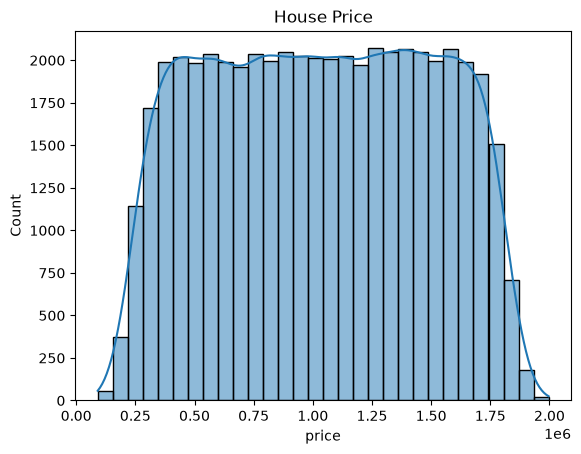

In [24]:
sns.histplot(x='price', data=df, bins=30, kde=True)
plt.title("House Price")
plt.show()

#### **Step 10. Correlation analysis**

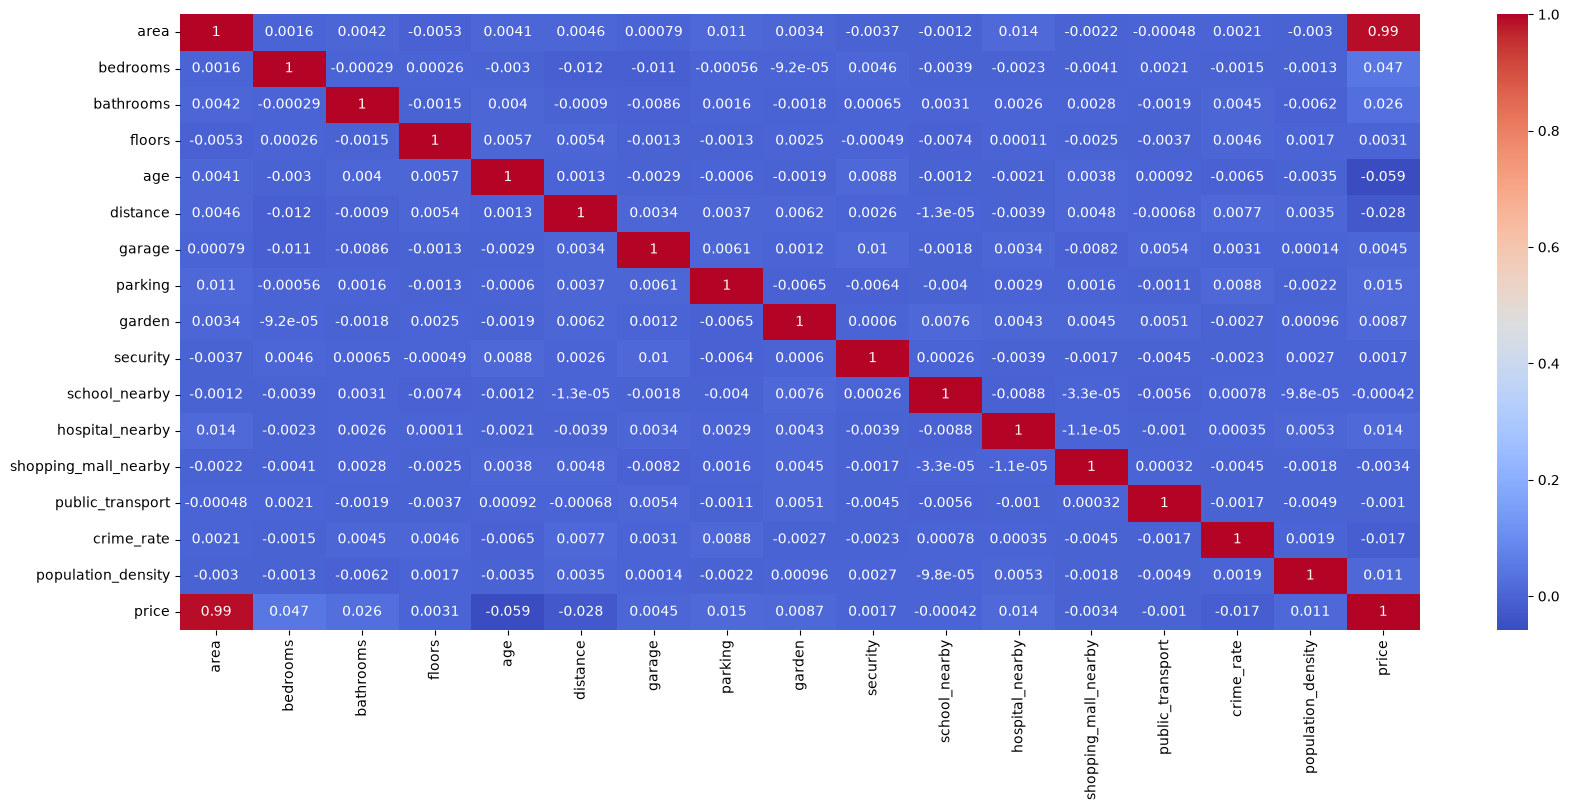

In [13]:
plt.figure(figsize=(20, 8))
corr_matrix = df.corr(numeric_only=True)
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.show()

**Step 11. Step 11: Features Highly Correlated with SalePrice**

In [16]:
corr = df[num_cols].corr()
corr_saleprice = corr["price"].sort_values(ascending=False)

corr_saleprice

price                   1.000000
area                    0.991364
bedrooms                0.047123
bathrooms               0.025626
parking                 0.015492
hospital_nearby         0.013600
population_density      0.010539
garden                  0.008736
garage                  0.004506
floors                  0.003135
security                0.001659
school_nearby          -0.000416
public_transport       -0.001022
shopping_mall_nearby   -0.003412
crime_rate             -0.016964
distance               -0.028118
age                    -0.058757
Name: price, dtype: float64

In [17]:
corr_saleprice.head(20)

price                   1.000000
area                    0.991364
bedrooms                0.047123
bathrooms               0.025626
parking                 0.015492
hospital_nearby         0.013600
population_density      0.010539
garden                  0.008736
garage                  0.004506
floors                  0.003135
security                0.001659
school_nearby          -0.000416
public_transport       -0.001022
shopping_mall_nearby   -0.003412
crime_rate             -0.016964
distance               -0.028118
age                    -0.058757
Name: price, dtype: float64

**Step 12: Pairplot of Important Features**

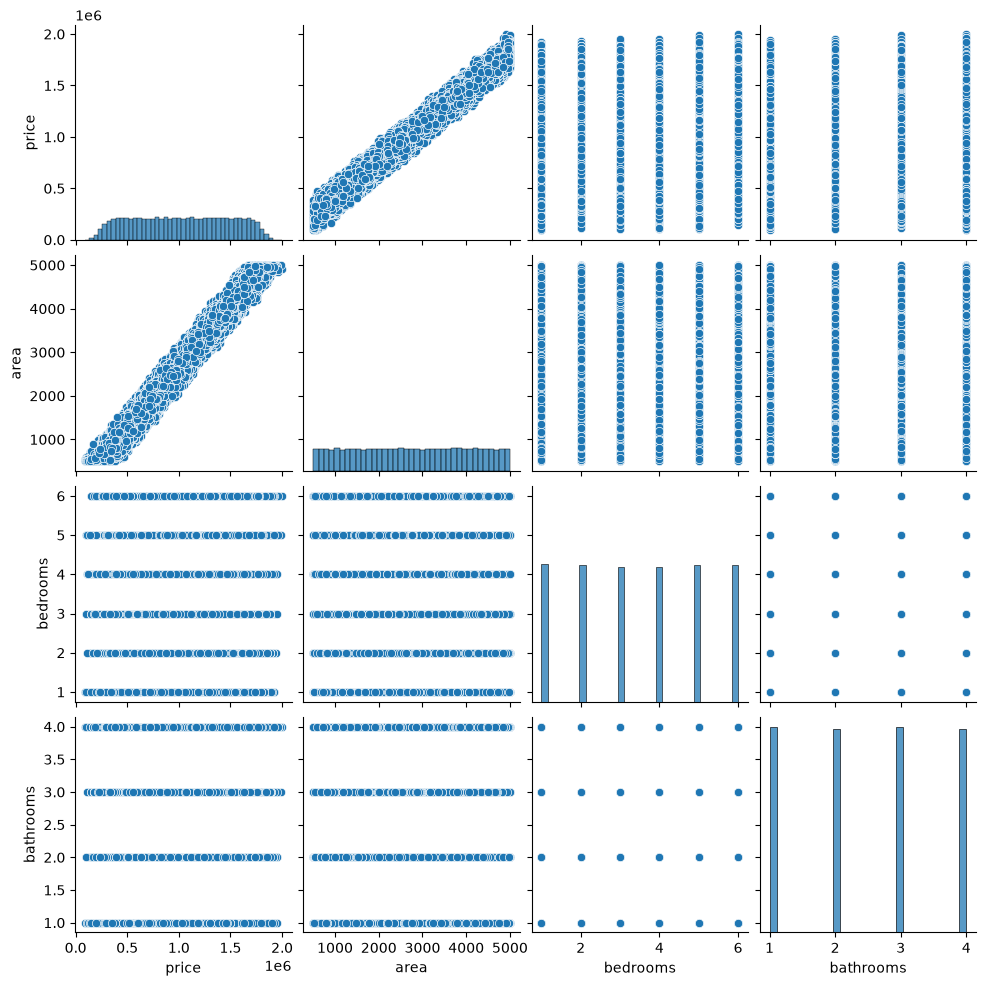

In [21]:
important = ["price","area","bedrooms","bathrooms"]
sns.pairplot(df[important])
plt.show()

**Step 13. outlier detection**

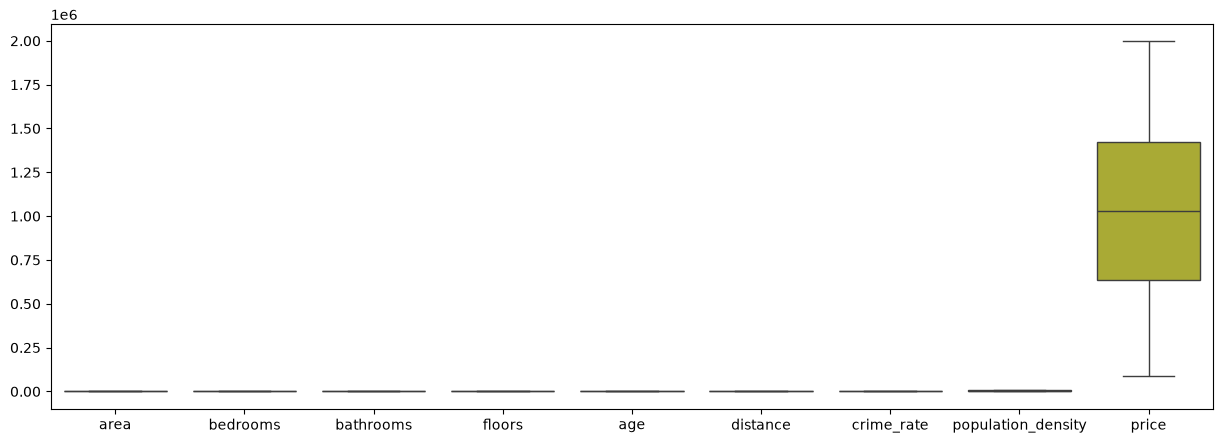

In [28]:
plt.figure(figsize=(15,5))
sns.boxplot(df[["area","bedrooms","bathrooms","floors","age","distance","crime_rate","population_density","price"]])
plt.show()

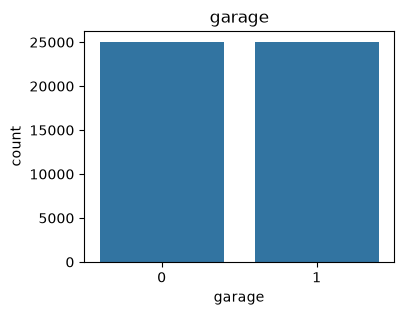

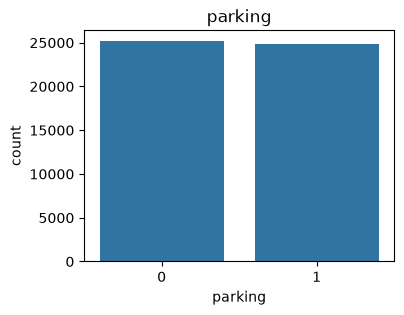

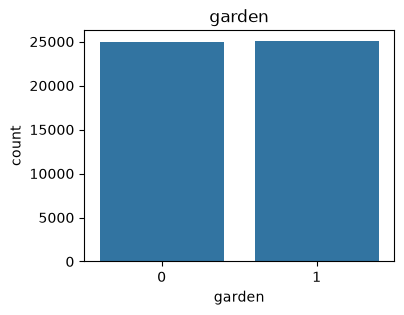

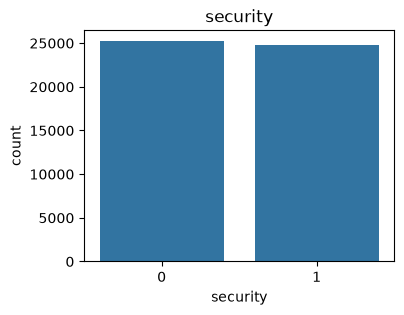

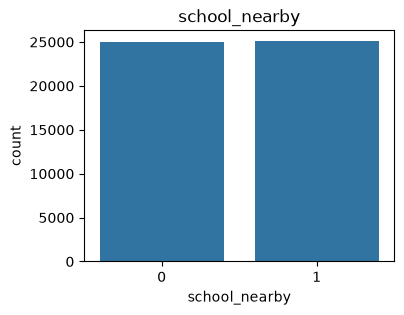

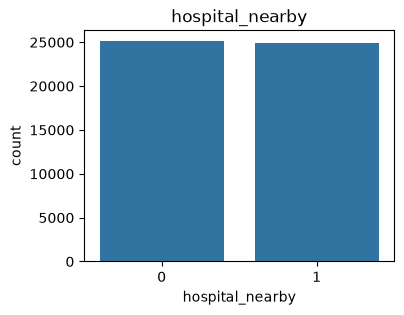

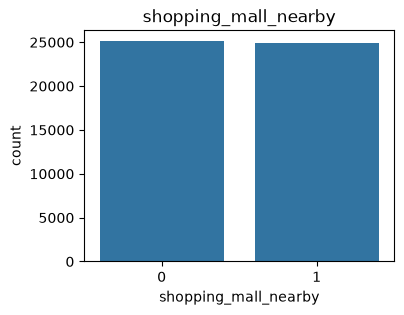

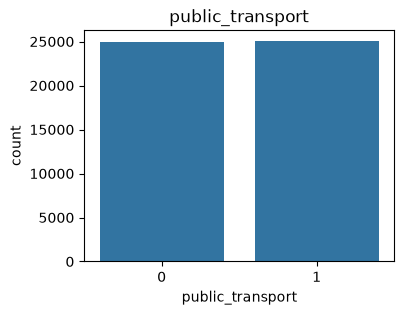

In [ ]:
binary = ["garage","parking","garden","security","school_nearby",
    "hospital_nearby","shopping_mall_nearby","public_transport"]

for col in binary:
    plt.figure(figsize=(4,3))
    sns.countplot(x=df[col])
    plt.title(col)
    plt.show()

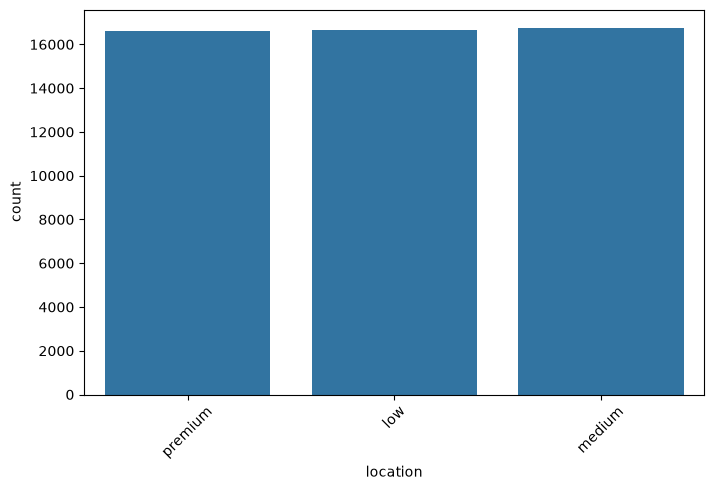

In [31]:
# Location Distribution
plt.figure(figsize=(8,5))
sns.countplot(x=df["location"])
plt.xticks(rotation=45)
plt.show()

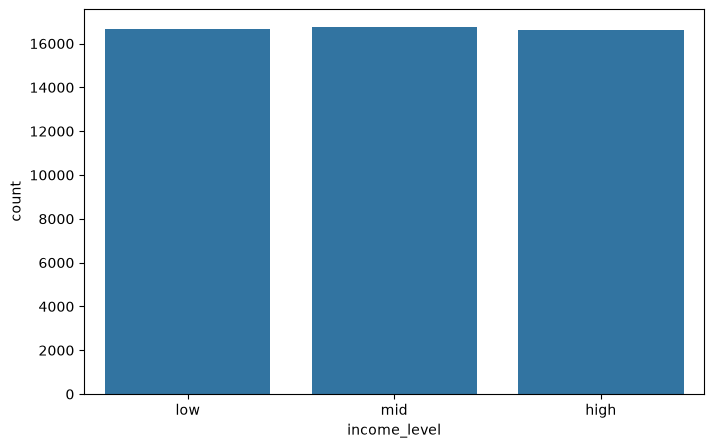

In [32]:
#Income Level Distribution
plt.figure(figsize=(8,5))
sns.countplot(x=df["income_level"])
plt.show()

#### **Step 14: Feature Engineering**

In [34]:
df["Area_per_Bedroom"] = df["area"] / df["bedrooms"]

df["Bathroom_per_Bedroom"] = df["bathrooms"] / df["bedrooms"]

df["LuxuryScore"] = (df["garden"] + df["security"] + df["garage"] + df["parking"] )

df["Accessibility"] = (df["school_nearby"] + df["hospital_nearby"] + df["shopping_mall_nearby"] + df["public_transport"])


#### **Step 15: Correlation of New Features**

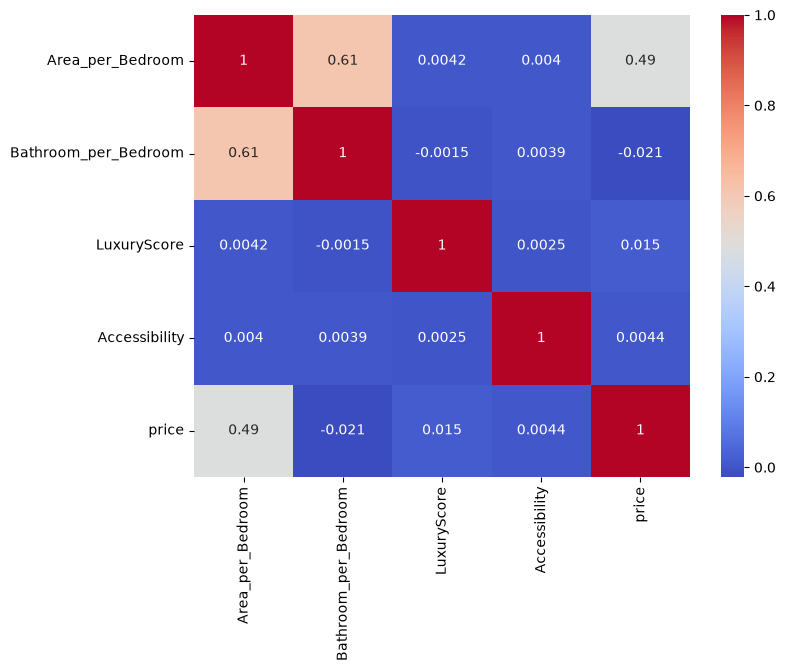

In [35]:
new_cols = ["Area_per_Bedroom","Bathroom_per_Bedroom","LuxuryScore","Accessibility","price"]

plt.figure(figsize=(8,6))
sns.heatmap(df[new_cols].corr(),annot=True,cmap="coolwarm")
plt.show()

#### **Step 16: Save Clean Dataset**

In [36]:
df.to_csv("D:/Deep Learning/Projects/ANN/2_House_ANN_Project/Data/house_clean.csv", index=False)
print("Dataset Saved Successfully")

Dataset Saved Successfully
